**Problem 2 - Noise**

So far, all of our data has been an ideal, noise-free case. For any practical purpose, this is unrealistic. Conditions are imperfect, wires are not at absolute zero, etc.. There will always be some level of background noise. Let's see how well our reconstruction works as we add noise into the mix. For simplicity, we will fix the number of resonances at $k=5$, and gradually increase the level of noise until it's signal strength is half that of the signal itself.

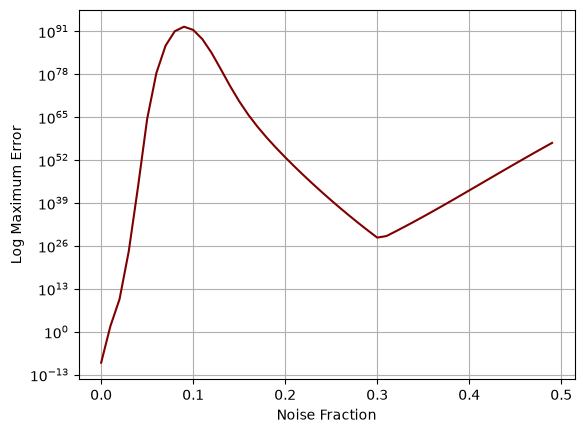

In [5]:
import pade_utils as pdu
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

delta_t = 0.01

def plot_error_graph(maximum_noise,  minimum_datapoints, resonances = 5):

    errors = []
    
    for noise in np.arange(0, maximum_noise, 0.01):
        true_signal = pdu.generate_synthetic_signal(order = resonances, noise_level = 0)
        noisy_signal = pdu.generate_synthetic_signal(order = resonances, noise_level = noise)
        reconstructed = pdu.pade_solve(noisy_signal, order = resonances, datapoints = minimum_datapoints)
        reconstructed_signal = np.sum(reconstructed, axis = 0)
    
        errors.append(np.max(np.abs(true_signal[:len(reconstructed_signal)] - reconstructed_signal)))
    
    x = np.arange(0, maximum_noise, 0.01)
    y = errors
    
    plt.plot(x, y, label = f"{minimum_datapoints}$k$ datapoints", color='maroon')
    
    
    plt.yscale('log')
    plt.grid(True, which='both')
    
    
    plt.xlabel(f"Noise Fraction")
    plt.ylabel("Log Maximum Error")


resonances = 5
plot_error_graph(maximum_noise = 0.5, resonances = 5, minimum_datapoints = 2 * resonances)
plt.show()

Ultimately, the effect of noise is similar to that of floating point errors, only much greater in amplitude. By overdetermining the problem, we can give the solver more information to work with, and constrict the solution space down. Let's fix our number of resonances, $k$, and noise level, and gradually increase how many datapoints we give to our solver.

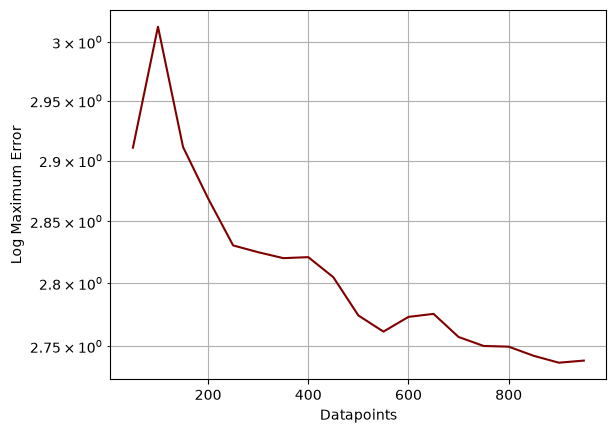

In [8]:
def plot_error_graph_k(noise_level, resonances, maximum_datapoints, minimum_datapoints = 50):

    errors = []
    
    for datapoints in np.arange(minimum_datapoints, maximum_datapoints, 50):
        true_signal = pdu.generate_synthetic_signal(order = resonances, noise_level = 0)
        noisy_signal = pdu.generate_synthetic_signal(order = resonances, noise_level = noise_level)
        reconstructed = pdu.pade_solve(noisy_signal, order = resonances, datapoints = datapoints)
        reconstructed_signal = np.sum(reconstructed, axis = 0)
    
        errors.append(np.max(np.abs(true_signal[:len(reconstructed_signal)] - reconstructed_signal)))
    
    x = np.arange(minimum_datapoints, maximum_datapoints, 50)
    y = errors
    
    plt.plot(x, y, color='maroon')
    
    
    plt.yscale('log')
    plt.grid(True, which='both')
    
    
    plt.xlabel(f"Datapoints")
    plt.ylabel("Log Maximum Error")

plot_error_graph_k(noise_level = 0.10, resonances = 10, maximum_datapoints = 1000)

This is an interesting feature of the graph. As we overdetermine the system, we initially see a huge fall in the error- to about the order of unity. This is not as good as we have seen on noise-free signals of course, but going just from $2k \rightarrow 3k$ datapoints does see a reduction in $\log$ error of ~ $100$ orders of magnitude, so it is -obviously- significant. More interestingly perhaps is what happens after this intial fall. We see a minimum error occur after only a relatively modest number of additional datapoints/ constraints are introduced, after which point the error begins to rise again. Why? 

Think about what happens to a noisy signal as the number of datapoints increases, and more and more of the FID is used. As the signal is made up of exponentially decaying resonances, the signal-to-noise ratio consistently falls as each signal decays. Yes, introducing more datapoints introduces more constraints for the graph, especially early on, but as we continue, we read in more and more noise to the graph as well. This is of critical importance when using real data, **the Pade approximation is not necessarily optimised by using all datapoints**. By reading in some optimum amount data, we can speed up the processing of signals with dynamic truncation, something we will explore in greater detail later on. Of course, in real NMR we do not know what the error compared to the real signal is, and we need to use more advanced techniques to try and distinguish noise from real signal.

One of the most interesting and unique feature of the Pade approximant when it comes to noise however, is in its use as an artefact/ de-noising tool. This requires us to think more deeply about our signal in the complex plane.

**How Does Noise Show Up in the Pade Approximant?**

Recall the generating function from which we read out the signals of the Pade Approximant : $$\mathcal{G}(w) = \sum_{k=1}^N \frac{d_k}{1 - \mathcal{z}_k w}$$
For perfect (zero-noise) data, every genuine signal $\mathcal{S}_n = d\mathcal{z}^n$ has a corresponding term in the generating function $\mathcal{G}(w) = \frac{d}{1 - \mathcal{z} w}$ and a pole at $w = \mathcal{z}^{-1}$. Crucially, even when we add noise, this signal should still exist, if slightly moved, as it is a real, underlying part of the signal. Of course, we do not exist ina  world of perfect, zero-noise data. 

Each signal is actually: $$\mathcal{S}_n \rightarrow \underbrace{\mathcal{S}_n}_{\operatorname{signal}} + \underbrace{\epsilon_n}_{\operatorname{noise}}$$

So how does the Pade approximant actually deal with this noise? As the function doesn't know what is real and what is noise, it tries to fit the data to this new $\mathcal{S}_n + \epsilon_n$. Imagine we introduce a term $$\frac{w- a}{w-b}$$ into the geenrting function. If $a=b$, then this obviously cancels, with no effect on the overall structure. If, however, $a \approx b$, we get a function that is very close to unity almost everywhere, except for a tiny, specific alteration to the function, which it uses to fit noise. This pole-zero pair is called a **Froissart Doublet**, and is conceptually similar to overfitting in Machine Learning (ML). As these are tiny alterations which don't represent any true underlying structure, we expect that even tiny changes to the signal would move thee about dramatically. This gives us two tests for noise: 

 - Is it a pole-zero pair (Froissart doublet)?
 - Is it highly unstable to perturbations?

Both of these are evidence (not an absolute reality), towards a point being noise rather than true signal. If we can de-weight points which seem more likely to be noise, can we de-noise spectra, and make even more reliable reconstructions of the signal?


**1 - Is It Part of a Pole-Zero Pair?**

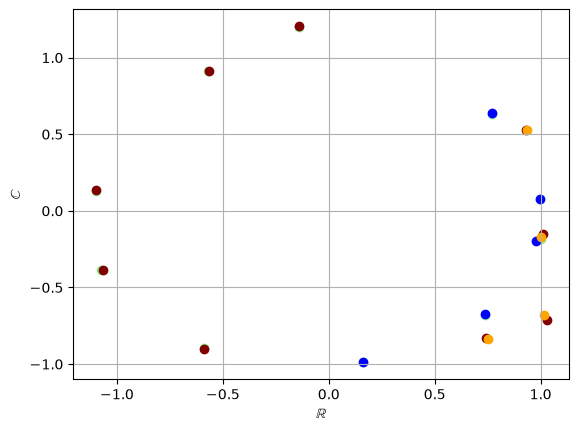

In [10]:
def signal_to_poles_and_zeros(signal, datapoints, elements):
    """
    A function that takes our signal (FID) and works through the linear algebra, to the point until we have determined the numerator P(w) and denominator Q(w).
    It returns the poles and zeros so we can do calculations wiht Froissart doubles.
    """
    
    # Get Q(w) coefficients
    signal_used = signal[:datapoints].tolist()
    empty_matrix = []
    rhs_vector = []

    for i in range(datapoints - elements):
        matrix_row = signal_used[i:elements+i]
        matrix_row.reverse()
        empty_matrix.append(matrix_row)
        rhs_vector.append( -1 * signal_used[elements+i])

    matrix = np.array(empty_matrix, dtype=complex)
    rhs_vector = np.array(rhs_vector, dtype=complex)

    scales = np.linalg.norm(matrix, axis = 0)
    matrix_scaled = matrix / scales

    q_k_scaled, _, _, _ = np.linalg.lstsq(matrix_scaled, rhs_vector, rcond=None)
    q_k = q_k_scaled / scales

    # Get P(w) coefficients
    q_ascending = np.append(1, q_k)

    p_k = []

    for n in range(elements):
        coefficient = 0

        for j in range(n + 1):
            coefficient += q_ascending[j] * signal_used[n - j]

        p_k.append(coefficient)

    p_k_coefficients = np.array(p_k[::-1], dtype=complex)
    q_k_coefficients = np.array(q_ascending[::-1], dtype=complex)

    poles = np.roots(q_k_coefficients)
    zeros = np.roots(p_k_coefficients)

    return poles, zeros

elements = 10

noisy_signal = pdu.generate_synthetic_signal(order = 5, noise_level = 0.10)
true_signal = pdu.generate_synthetic_signal(order = 5, noise_level = 0)
        
poles, zeros = signal_to_poles_and_zeros(noisy_signal, datapoints= 50, elements = elements)
true_poles, true_zeros = signal_to_poles_and_zeros(true_signal, datapoints= 50, elements = 5)

plt.scatter(poles.real, poles.imag, color='lightgreen')
plt.scatter(zeros.real, zeros.imag, color='maroon')

plt.scatter(true_poles.real, true_poles.imag, color='blue')
plt.scatter(true_zeros.real, true_zeros.imag, color='orange')


plt.xlabel("$\\mathbb{R}$")
plt.ylabel("$\\mathbb{C}$")

plt.grid()

plt.show()

Here we have overdetermined a system. We know the true signal has five resonances, but we tell our function to deconstruct it to ten signals. The spurious signals then show up in the complex plane as pole-zero pairs. It is however, perhaps not immediately obvious (and certainly will not be for more complex signals), which of the points are indeed Froissart doubles, and which are genuine. This problem indeed, would be worsened when using real data, where we often have no clear idea how many resonances we expect. Still, a crude method of detection is simply eliminating any pole zero pairs over a threshold.

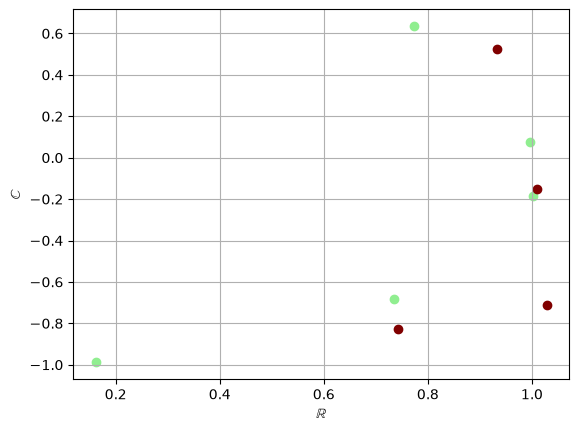

In [11]:
def froissart_clean(poles, zeros, threshold=0.05):
    """
    This takes the poles and zeros from the previous function and eliminates any which are closer than a threshold value.
    """
    
    distance_matrix = np.abs(poles[:, None] - zeros[None, :])

    pole_indices, zero_indices = linear_sum_assignment(distance_matrix)

    remove_poles = []
    remove_zeros = []

    for p_idx, z_idx in zip(pole_indices, zero_indices):

        if distance_matrix[p_idx, z_idx] < threshold:
            remove_poles.append(p_idx)
            remove_zeros.append(z_idx)

    cleaned_poles = np.delete(poles, remove_poles)
    cleaned_zeros = np.delete(zeros, remove_zeros)

    return cleaned_poles, cleaned_zeros

cleaned_poles, cleaned_zeros = froissart_clean(poles = poles, zeros = zeros)

plt.scatter(cleaned_poles.real, cleaned_poles.imag, color='lightgreen')
plt.scatter(cleaned_zeros.real, cleaned_zeros.imag, color='maroon')

plt.xlabel("$\\mathbb{R}$")
plt.ylabel("$\\mathbb{C}$")

plt.grid(True)

plt.show()

This coarse approach seems promising. By removing the pole-zero pairs, we are left with five poles, for our noisy signal with five resonances. By reconstructing the signal using these cleaned poles and zeros, we should hope to see some form of de-noising of the overall signal. We now need to re-code the rest of our pade solver- going from poles and zeros back through to reconstructed resonances. 

In [12]:
def signal_from_poles_zeros(poles, zeros, signal, datapoints, delta_t = 0.01, tmax = 1000):
    """
    Reconstructs the signal from poles and zeros. Returns the signal as a numpy array.
    """
    empty_matrix = []
    rhs_vector = []
    
    z_k = [(1/pole) for pole in poles]
    
    for i in range(datapoints):
        matrix_row = [z**i for z in z_k]
        empty_matrix.append(matrix_row)
        rhs_vector.append(signal[i])

    matrix = np.array(empty_matrix, dtype=complex)
    rhs_vector = np.array(rhs_vector, dtype=complex)

    scales = np.linalg.norm(matrix, axis = 0)
    matrix_scaled = matrix / scales

    d_k_scaled, _, _, _ = np.linalg.lstsq(matrix_scaled, rhs_vector, rcond=None)
    d_k = d_k_scaled / scales

    mag = np.abs(z_k)
    arg = np.angle(z_k, deg=False)

    Lambda = - (np.log(mag)) / delta_t
    Frequency = arg / (2*np.pi*delta_t)

    Amplitude = np.abs(d_k)
    Phase = np.angle(d_k, deg=False)

    assert len(z_k) == len(d_k)

    individual_signals = []

    for z, d in zip(z_k, d_k):

        signal = []

        for n in range(tmax):
            signal.append(d * z**n)

        individual_signals.append(signal)

    individual_signals = np.array(individual_signals, dtype=complex)

    return individual_signals

def reconstruct_froissart(signal, order, datapoints, threshold):

    poles, zeros = signal_to_poles_and_zeros(signal, datapoints, elements = order)
    cleaned_poles, cleaned_zeros = froissart_clean(poles = poles, zeros = zeros, threshold = threshold)

    cleaned_signals = signal_from_poles_zeros(cleaned_poles, cleaned_zeros, signal = signal, datapoints = datapoints)
    summed_signal = np.sum(cleaned_signals, axis = 0)

    return summed_signal

    

In [15]:
true_signal = pdu.generate_synthetic_signal(order = 10, noise_level = 0)
noisy_signal = pdu.generate_synthetic_signal(order = 10, noise_level = 0.5)

reconstructed_pade = pdu.pade_solve(noisy_signal, order = 30, datapoints = 200)
pade_signal = np.sum(reconstructed_pade, axis = 0)

cleaned_signal = reconstruct_froissart(signal = noisy_signal, order = 30, datapoints = 200, threshold = 0.05)

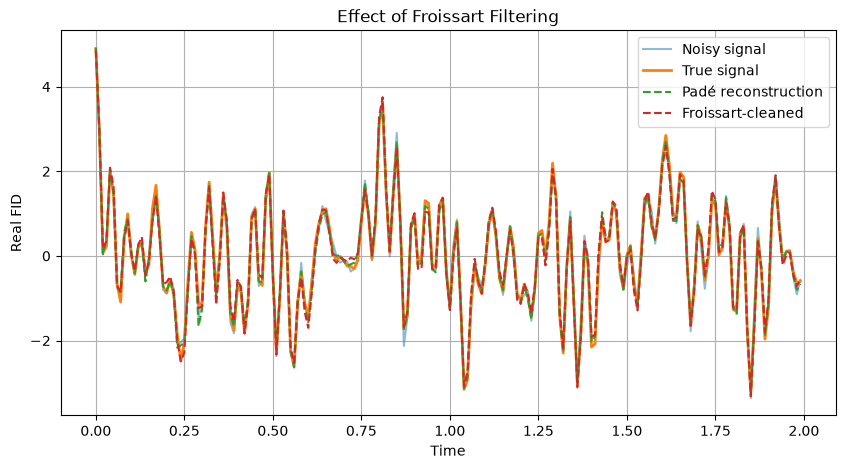

Noisy signal RMSE:        0.207373
Padé reconstruction RMSE: 0.628805
Froissart-cleaned RMSE:   0.637111


In [17]:
n_plot = 200
time = np.arange(len(true_signal)) * delta_t

plt.figure(figsize=(10, 5))

plt.plot(time[:n_plot], np.real(noisy_signal[:n_plot]), alpha=0.5,label="Noisy signal")
plt.plot(time[:n_plot], np.real(true_signal[:n_plot]), linewidth=2,label="True signal")
plt.plot(time[:n_plot], np.real(pade_signal[:n_plot]), linestyle="--", label="Padé reconstruction")
plt.plot(time[:n_plot], np.real(cleaned_signal[:n_plot]), linestyle="--", label="Froissart-cleaned")

plt.xlabel("Time")
plt.ylabel("Real FID")
plt.title("Effect of Froissart Filtering")
plt.grid(True)
plt.legend()
plt.show()

def rmse(a, b):
    return np.sqrt(np.mean(np.abs(a - b)**2))

n_compare = min(len(true_signal),len(noisy_signal),len(pade_signal), len(cleaned_signal))

print(f"Noisy signal RMSE:        {rmse(true_signal[:n_compare], noisy_signal[:n_compare]):.6f}")
print(f"Padé reconstruction RMSE: {rmse(true_signal[:n_compare], pade_signal[:n_compare]):.6f}")
print(f"Froissart-cleaned RMSE:   {rmse(true_signal[:n_compare], cleaned_signal[:n_compare]):.6f}")

**What's Happening Here?**

**2 - Pole Instability**

Ok. We have signal to poles and zeros which takes datapoints as an argument. See, as we add in more and more of the data, which poles move around a lot, and which don't. Let's get some data first before figuring out how to filter these.

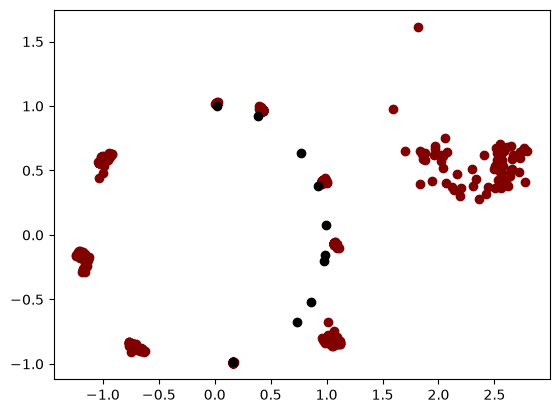

In [19]:
# We have signal_to_poles_and_zeros(signal, datapoints, elements)
# So just loop this and see how poles change I suppose. How to measure this?

true_signal = pdu.generate_synthetic_signal(order = 10, noise_level = 0)
noisy_signal = pdu.generate_synthetic_signal(order = 10, noise_level = 0.5)

true_poles = signal_to_poles_and_zeros(true_signal, datapoints = 200, elements = 10)[0]

for datapoints in np.arange(40, 400, 5):
    
    poles = signal_to_poles_and_zeros(noisy_signal, datapoints = datapoints, elements = 10)[0]
    plt.scatter(poles.real, poles.imag, color='maroon')


plt.scatter(true_poles.real, true_poles.imag, color='black')
plt.show()